## Importacion de Librerias

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Lectura Archivo


In [8]:
df = pd.read_csv('Base_de_datos.csv')

In [9]:
df.head()
df.describe


<bound method DataFrame.describe of        tipo_credito       fecha_prestamo  capital_prestado  plazo_meses  \
0                 4  2025-01-07 14:40:36         1852560.0           12   
1                 4  2025-01-09 11:18:48         3181080.0            6   
2                 9  2024-12-26 18:52:57          670200.0            5   
3                 9  2024-12-04 14:20:50          506806.8            2   
4                 4  2025-04-30 18:41:57          999780.0           10   
...             ...                  ...               ...          ...   
10758             9  2024-12-18 09:32:36         1269000.0            8   
10759             9  2025-01-16 10:57:01          640880.4            9   
10760             9  2025-04-19 14:41:28          586680.0            5   
10761             9  2024-12-06 15:15:07         1084186.8            5   
10762             9  2024-12-13 16:55:44         1084186.8            2   

       edad_cliente   tipo_laboral  salario_cliente  total_otro

--- Estadísticas y Dispersión ---
                                       mean           50%           std  \
capital_prestado               2.434315e+06  1.921920e+06  1.909643e+06   
plazo_meses                    1.057558e+01  1.000000e+01  6.632082e+00   
edad_cliente                   4.394862e+01  4.200000e+01  1.506088e+01   
salario_cliente                1.721643e+07  3.000000e+06  3.554767e+08   
total_otros_prestamos          6.238870e+06  1.000000e+06  1.184183e+08   
cuota_pactada                  2.436174e+05  1.828630e+05  2.104937e+05   
puntaje                        9.117004e+01  9.522779e+01  1.646544e+01   
puntaje_datacredito            7.807908e+02  7.910000e+02  1.048780e+02   
cant_creditosvigentes          5.726749e+00  5.000000e+00  3.977162e+00   
huella_consulta                4.228561e+00  4.000000e+00  3.064683e+00   
saldo_mora                     7.746017e+00  0.000000e+00  2.259551e+02   
saldo_total                    4.593741e+04  1.617800e+04  1.06269

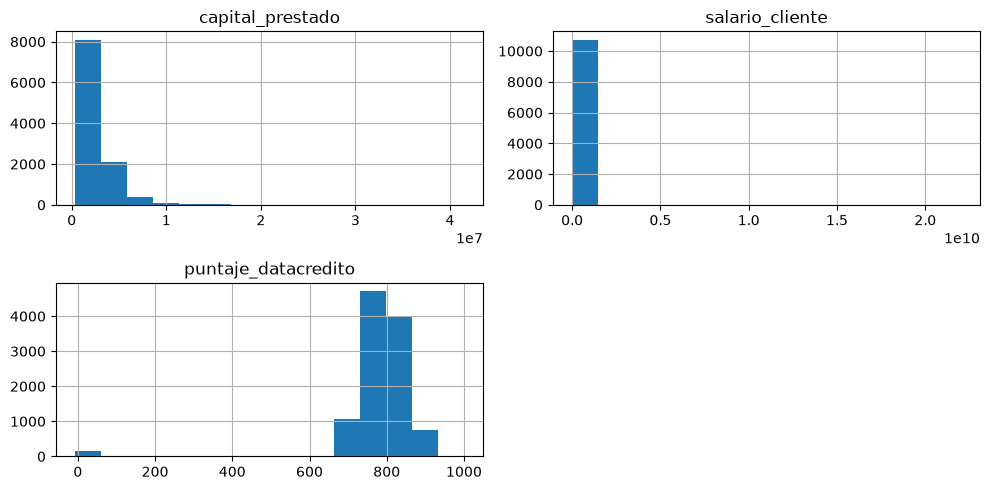

C:\Users\david\AppData\Local\Temp\ipykernel_13340\1902067853.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Pago_atiempo', y='puntaje_datacredito', palette='Set2')


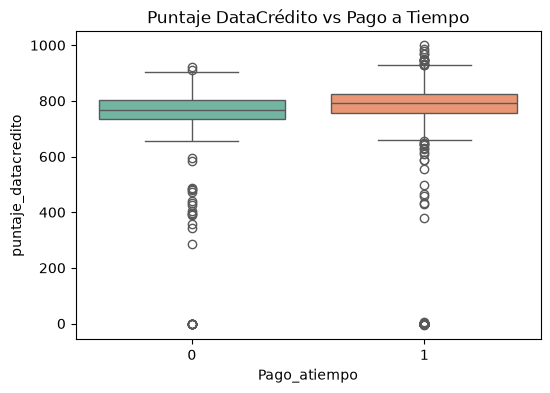

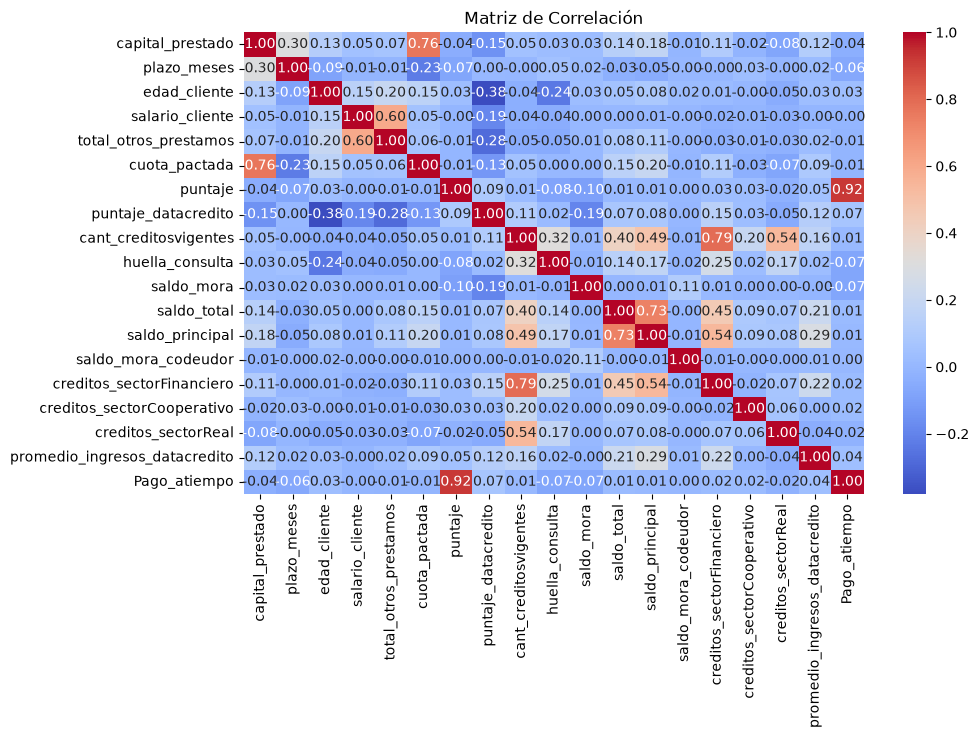

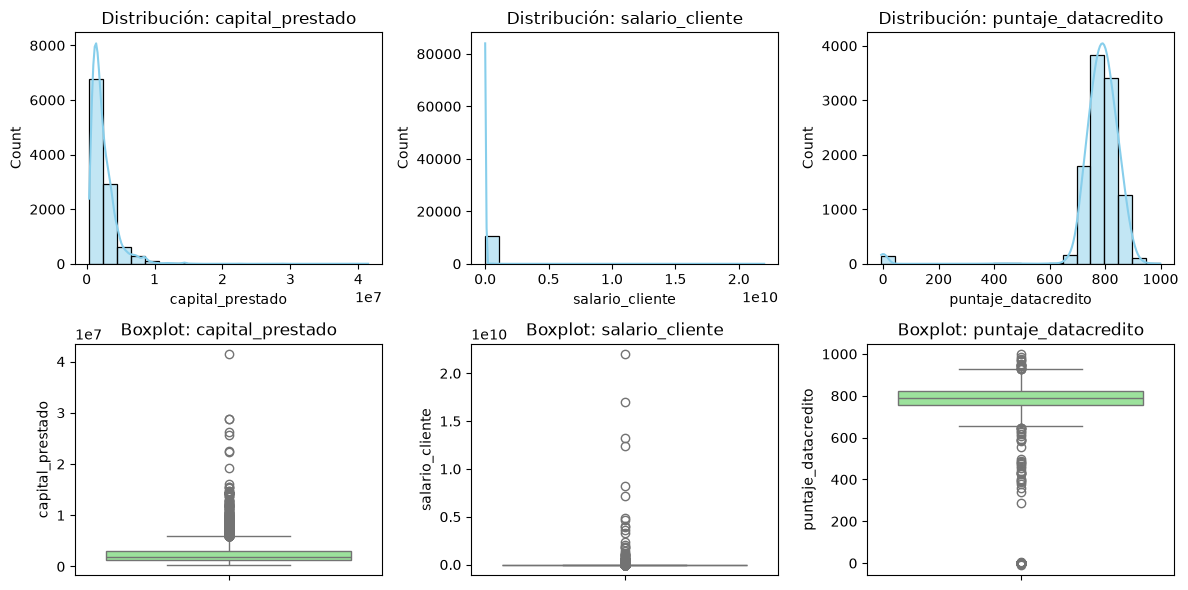

In [ ]:
# 1. Limpieza y Tipos de Datos
df.replace(['None', 'NULL', 'nan', 'N/A', ''], np.nan, inplace=True)
if 'fecha_prestamo' in df.columns:
    df['fecha_prestamo'] = pd.to_datetime(df['fecha_prestamo'])

for col in ['tipo_credito', 'tipo_laboral', 'tendencia_ingresos']:
    if col in df.columns:
        df[col] = df[col].astype('category')

# 2. Análisis Univariable (Numéricas)
num_cols = df.select_dtypes(include=[np.number]).columns
print("--- Estadísticas y Dispersión ---")
stats = df[num_cols].describe().T
stats['IQR'] = stats['75%'] - stats['25%']
stats['skewness'] = df[num_cols].skew()
print(stats[['mean', '50%', 'std', 'min', 'max', 'IQR', 'skewness']])

# Gráficos básicos de distribución
df[['capital_prestado', 'salario_cliente', 'puntaje_datacredito']].hist(bins=15, figsize=(10, 5))
plt.tight_layout()
plt.show()

# 3. Análisis Bivariable con la variable objetivo (Pago_atiempo)
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x='Pago_atiempo', y='puntaje_datacredito', palette='Set2')
plt.title('Puntaje DataCrédito vs Pago a Tiempo')
plt.show()

# Matriz de correlación
plt.figure(figsize=(10, 6))
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Matriz de Correlación')
plt.show()

# Visualización univariable: Histogramas y Boxplots
plt.figure(figsize=(12, 6))
for i, col in enumerate(['capital_prestado', 'salario_cliente', 'puntaje_datacredito'], 1):
    if col in df.columns:
        plt.subplot(2, 3, i)
        sns.histplot(df[col], kde=True, bins=20, color='skyblue')
        plt.title(f'Distribución: {col}')
        
        plt.subplot(2, 3, i + 3)
        sns.boxplot(y=df[col], color='lightgreen')
        plt.title(f'Boxplot: {col}')
plt.tight_layout()
plt.show()

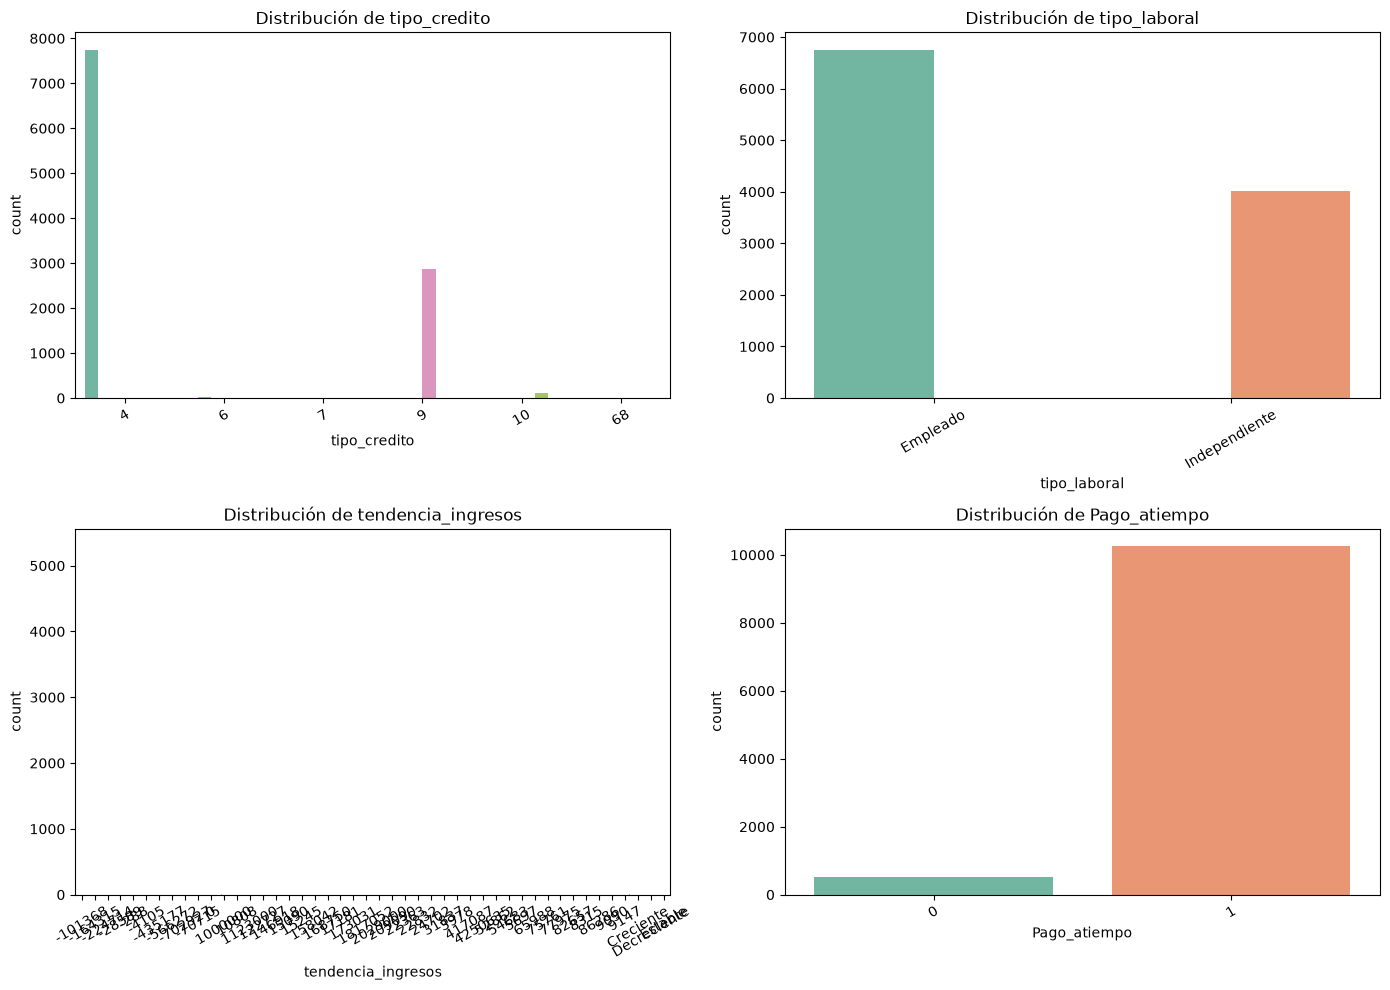

,Proporción
tipo_credito,
4,0.719781
9,0.267212
10,0.010778
6,0.001951
7,0.000186
68,0.000093


,Proporción
tipo_laboral,
Empleado,0.62752
Independiente,0.37248


,Proporción
tendencia_ingresos,
Creciente,0.676031
Decreciente,0.164858
Estable,0.151705
0,0.000894
8315,0.000766
1000000,0.000511
9147,0.000255
-101368,0.000128
-164315,0.000128


,Proporción
Pago_atiempo,
1,0.952523
0,0.047477


In [11]:
# Gráficos de conteo para variables categóricas
cat_cols = ['tipo_credito', 'tipo_laboral', 'tendencia_ingresos', 'Pago_atiempo']

plt.figure(figsize=(14, 10))
for i, col in enumerate(cat_cols, 1):
    if col in df.columns:
        plt.subplot(2, 2, i)
        sns.countplot(data=df, x=col, palette='Set2', hue=col, legend=False)
        plt.title(f'Distribución de {col}')
        plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Resumen de frecuencias relativas
for col in cat_cols:
    if col in df.columns:
        display(df[col].value_counts(normalize=True).rename("Proporción").to_frame())

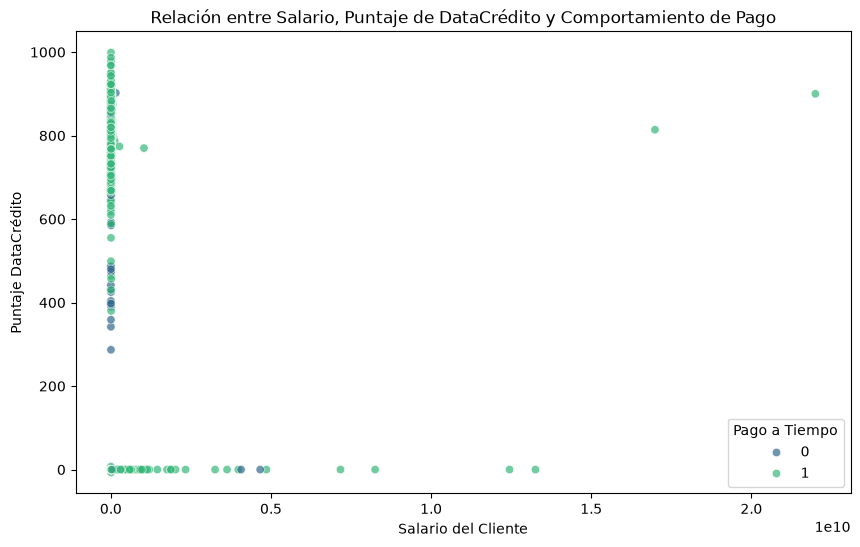

In [17]:
# Gráfico de dispersión multivariable usando 'hue' para la variable objetivo
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df, 
    x='salario_cliente', 
    y='puntaje_datacredito', 
    hue='Pago_atiempo', 
    palette='viridis', 
    alpha=0.7
)
plt.title('Relación entre Salario, Puntaje de DataCrédito y Comportamiento de Pago')
plt.xlabel('Salario del Cliente')
plt.ylabel('Puntaje DataCrédito')
plt.legend(title='Pago a Tiempo')
plt.show()

# 4. Análisis Multivariable
